# Sector ETF realised volatility EDA

Display a summary table and monthly line chart for **XLB, XLE, XLF, XLI, and XLY** using `realized_variance.csv` in this directory. All statistics and plotted points are calculated from the data.

The reference values use **annualised volatility in percent**, observed monthly. This notebook uses the same convention.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Locate the data when running from this folder or elsewhere in the repository.
PROJECT_ROOT = next(
    (path for path in [Path.cwd(), *Path.cwd().parents]
     if (path / 'dataset/price/clean/realized_variance.csv').is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Run this notebook from within the project directory.')
CLEAN_DIR = PROJECT_ROOT / 'dataset/price/clean'

TICKERS = ['XLB', 'XLE', 'XLF', 'XLI', 'XLY']
SECTOR_NAMES = {
    'XLB': 'Materials',
    'XLE': 'Energy',
    'XLF': 'Financials',
    'XLI': 'Industrials',
    'XLY': 'Cons. discretionary',
}
COLORS = {
    'XLB': '#D2A33F',
    'XLE': '#B16C40',
    'XLF': '#27265D',
    'XLI': '#6B8DA5',
    'XLY': '#739086',
}
TEXT_COLOR = '#333333'
BACKGROUND = '#FFFFFF'
MONTHS_PER_YEAR = 12

# Enable to save both figures and the numeric summary beside this notebook.
EXPORT_OUTPUTS = False
OUTPUT_DIR = CLEAN_DIR / 'eda_outputs'

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'text.color': TEXT_COLOR,
    'axes.labelcolor': TEXT_COLOR,
    'xtick.color': TEXT_COLOR,
    'ytick.color': TEXT_COLOR,
    'figure.facecolor': BACKGROUND,
    'axes.facecolor': BACKGROUND,
})

## Convert monthly realised variance to annualised volatility

`../calculate_realized_variance.py` constructs `rv_1m` as the monthly sum of squared **daily excess returns** from `daily_returns_panel_ver2.csv`. Returns are decimals. Partial January 2003 is excluded upstream.

$$RV_{i,m}=\sum_{d\in m}(r_{i,d}-r_{f,d})^2,\qquad
\sigma^{\mathrm{ann}}_{i,m}(\%)=100\sqrt{12\,RV_{i,m}}.$$

Each point represents one month's realised volatility, expressed at an annual rate. Summary statistics are computed **after** the square-root transformation, across the full available monthly sample.

In [2]:
rv = pd.read_csv(
    CLEAN_DIR / 'realized_variance.csv',
    usecols=['date', 'etf', 'rv_1m'],
    parse_dates=['date'],
)
rv = rv.loc[rv['etf'].isin(TICKERS)].copy()
if rv.empty or rv['date'].isna().any() or rv.duplicated(['date', 'etf']).any():
    raise ValueError('Expected valid, unique ETF-month observations.')

monthly_variance = (
    rv.pivot(index='date', columns='etf', values='rv_1m')
    .reindex(columns=TICKERS)
    .sort_index()
)
expected_months = pd.date_range(
    monthly_variance.index.min(), monthly_variance.index.max(), freq='ME'
)
if not monthly_variance.index.equals(expected_months):
    raise ValueError('Expected consecutive month-end dates without gaps.')
if not np.isfinite(monthly_variance.to_numpy()).all() or (monthly_variance < 0).any().any():
    raise ValueError('All five ETFs must have finite, non-negative monthly variances.')

volatility_pct = 100 * np.sqrt(MONTHS_PER_YEAR * monthly_variance)
print(f'Sample: {volatility_pct.index.min():%b %Y} to {volatility_pct.index.max():%b %Y}')
print(f'{len(volatility_pct):,} months per ETF; {volatility_pct.size:,} observations in total.')
print('Units: annualised volatility (%). No missing ETF-month observations.')

Sample: Feb 2003 to Dec 2025
275 months per ETF; 1,375 observations in total.
Units: annualised volatility (%). No missing ETF-month observations.


## Summary table

`N` counts monthly observations. Mean, median, minimum, and maximum are annualised volatility in percent; `SD pp` is the sample standard deviation (`ddof=1`) in percentage points. Values are displayed to one decimal place, while `summary_stats` retains full precision. The table background is transparent.


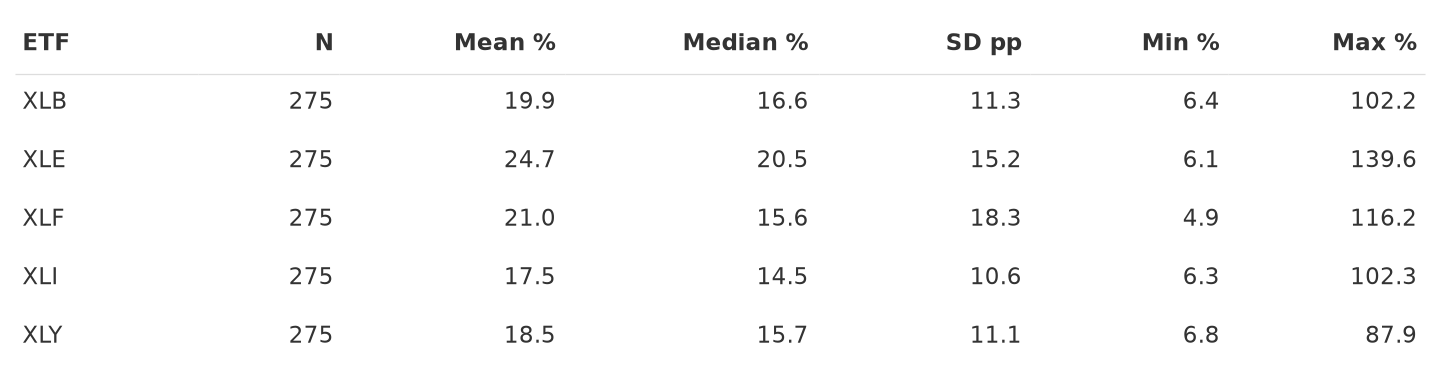

In [3]:
summary_stats = (
    volatility_pct.agg(['count', 'mean', 'median', 'std', 'min', 'max']).T
    .rename(columns={
        'count': 'N', 'mean': 'Mean %', 'median': 'Median %',
        'std': 'SD pp', 'min': 'Min %', 'max': 'Max %',
    })
    .reindex(TICKERS)
    .astype({'N': int})
)
summary_stats.index.name = 'ETF'

table_rows = [
    [ticker, str(summary_stats.loc[ticker, 'N'])]
    + [f'{value:.1f}' for value in summary_stats.loc[ticker].drop('N')]
    for ticker in TICKERS
]
table_fig, table_ax = plt.subplots(figsize=(10, 2.6), dpi=150)
table_fig.patch.set_alpha(0)
table_ax.axis('off')
table = table_ax.table(
    cellText=table_rows,
    colLabels=['ETF', *summary_stats.columns],
    cellLoc='right',
    colLoc='right',
    colWidths=[0.13, 0.10, 0.16, 0.18, 0.15, 0.14, 0.14],
    bbox=[0, 0, 1, 1],
)
table.auto_set_font_size(False)
table.set_fontsize(11)
for (row, col), cell in table.get_celld().items():
    cell.set_facecolor('none')
    cell.set_edgecolor('#DDDDDD')
    cell.set_linewidth(0.6)
    cell.visible_edges = 'B' if row == 0 else ''
    cell.PAD = 0.04
    cell.set_text_props(color=TEXT_COLOR, weight='bold' if row == 0 else 'normal')
    if col == 0:
        cell.set_text_props(ha='left')
table_fig.subplots_adjust(left=0.03, right=0.97, bottom=0.05, top=0.95)
display(table_fig)
plt.close(table_fig)


## Monthly realised volatility (%)

Each line connects consecutive monthly observations for one ETF. Colours follow the summary table's ticker order. The vertical scale uses the annualised percentage values defined above.


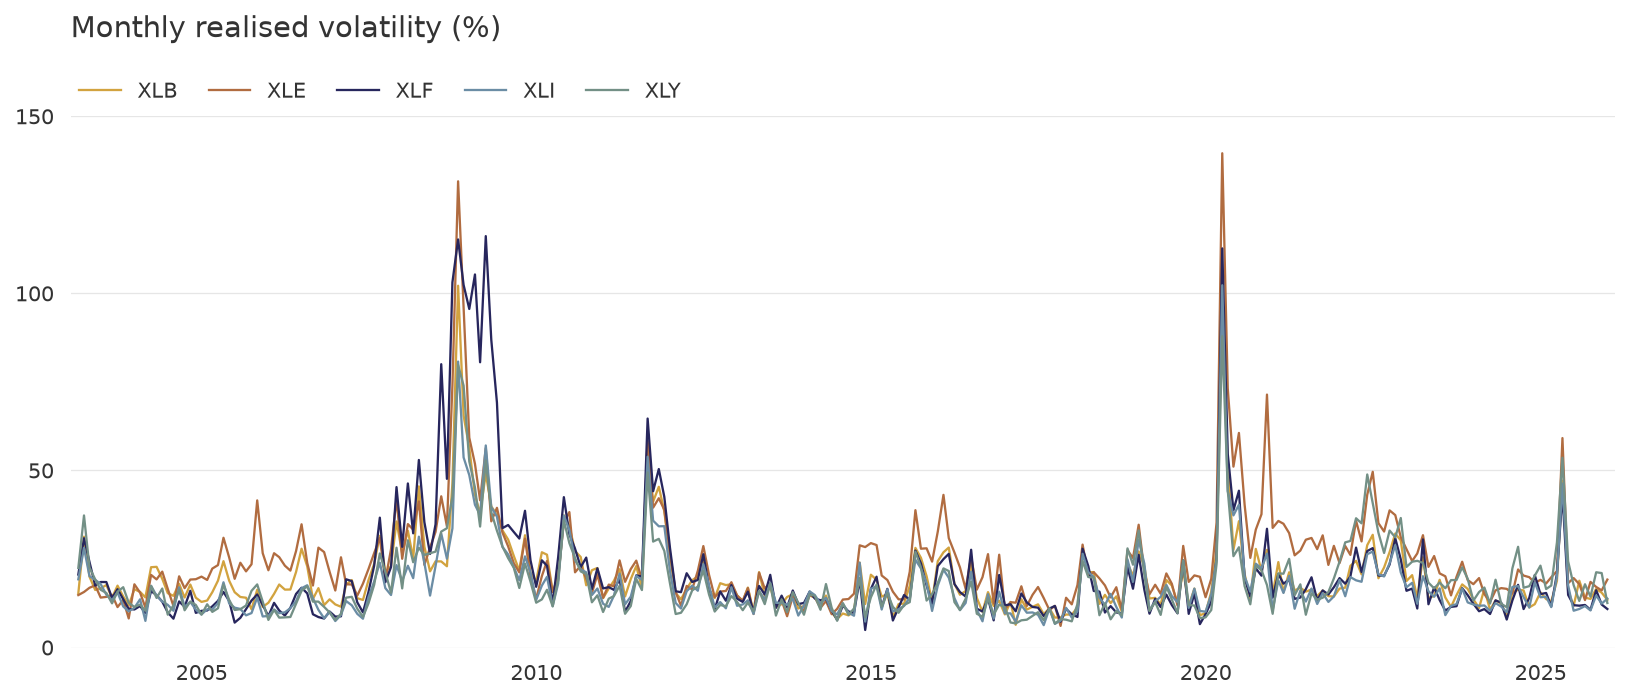

In [4]:
chart_fig, chart_ax = plt.subplots(figsize=(11, 4.8), dpi=150)

for ticker in TICKERS:
    chart_ax.plot(
        volatility_pct.index, volatility_pct[ticker],
        color=COLORS[ticker], linewidth=1.1, label=ticker, zorder=3,
    )

chart_ax.set_title('Monthly realised volatility (%)', loc='left', fontsize=14, pad=38)
chart_ax.legend(
    loc='lower left', bbox_to_anchor=(0, 1.01), borderaxespad=0,
    ncol=len(TICKERS), frameon=False, fontsize=10, handlelength=2,
    columnspacing=1.5,
)

chart_ax.xaxis.set_major_locator(mdates.YearLocator(base=5))
chart_ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
chart_ax.margins(x=0.005)
y_max = max(150, 50 * np.ceil(volatility_pct.to_numpy().max() / 50))
chart_ax.set_ylim(0, y_max)
chart_ax.set_yticks(np.arange(0, y_max + 1, 50))
chart_ax.tick_params(axis='both', length=0, pad=8)
chart_ax.grid(True, axis='y', color='#E6E6E6', linewidth=0.6)
chart_ax.set_axisbelow(True)
for spine in chart_ax.spines.values():
    spine.set_visible(False)
chart_fig.tight_layout(pad=1.2)

display(chart_fig)
plt.close(chart_fig)
